# Example of the aitlas toolbox in the context of semantic segmentation

Note: the original images are tiled as 1280 x 1280 patches to increase the amount of training examples.

## Import the required packages

In [ ]:
from aitlas.datasets import GLHWaterDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 25000


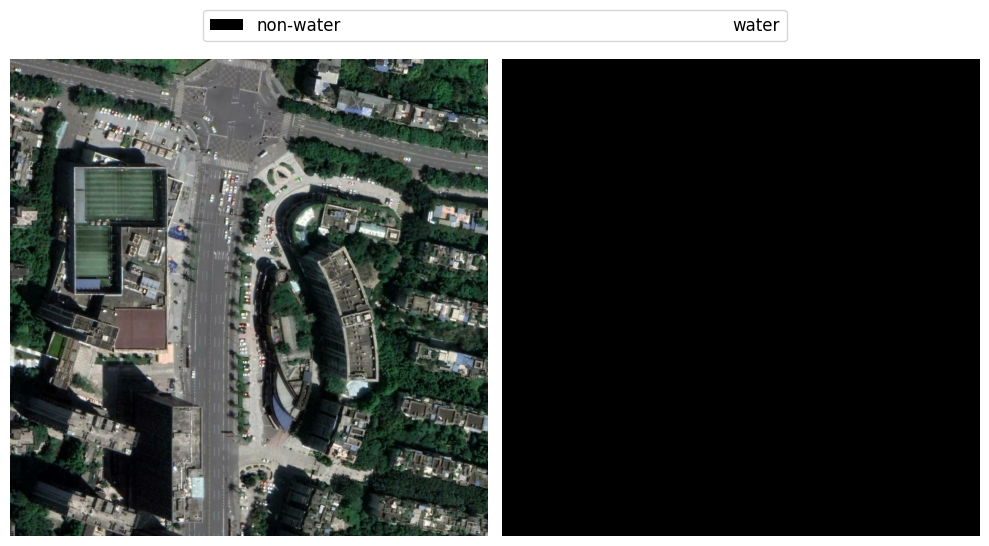

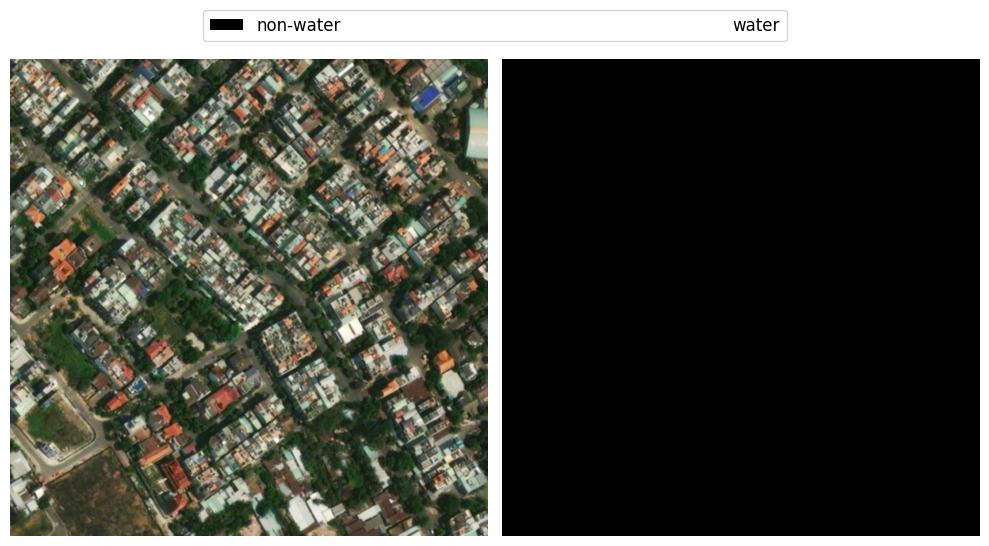

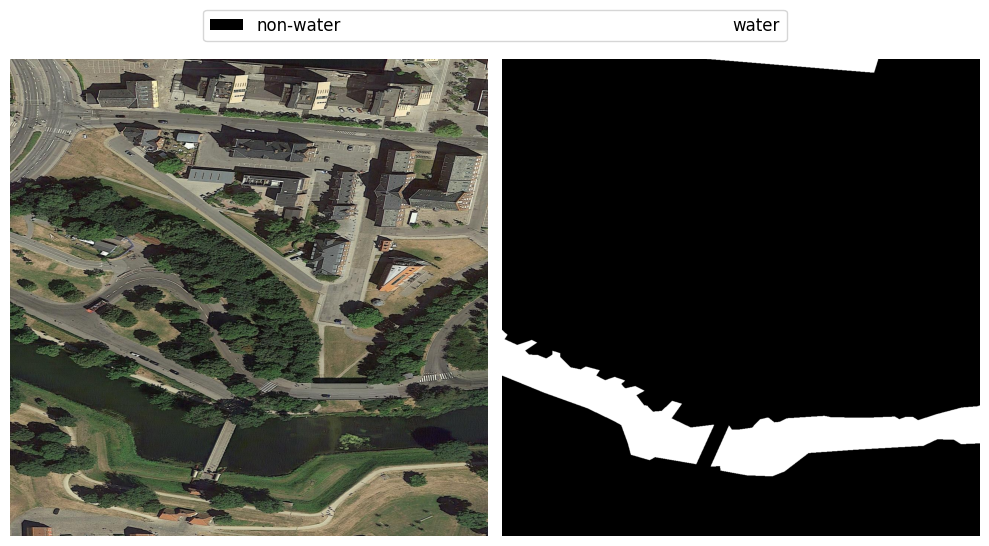

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/GLH_Water"
}
dataset = GLHWaterDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(500);
dataset.show_image(100);

In [7]:
dataset.data_distribution_table()

,Number of pixels
non-water,3.471982e+10
water,6.240182e+09


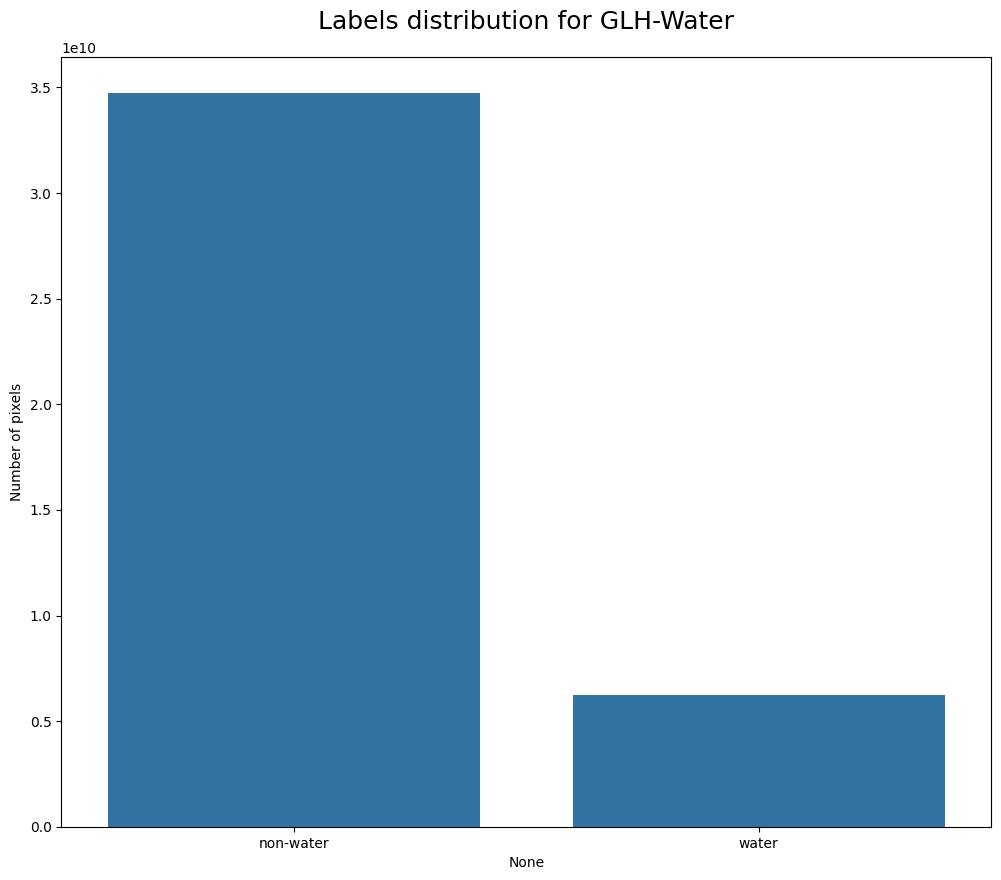

In [8]:
dataset.data_distribution_barchart();

## Load training data

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/GLH_Water",
    "csv_file": "/home/dragik/data/FAIR_EO/GLH_Water/glh_water_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = GLHWaterDataset(train_dataset_config)
len(train_dataset)

15000

## Create the model

In [6]:
epochs = 1
model_directory = "/home/dragik/data/FAIR_EO/experiments/GLH_Water"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-01-13 09:14:22,400 INFO Starting training.
training: 100%|██████████| 1875/1875 [5:08:29<00:00,  9.87s/it]
2026-01-13 14:22:51,742 INFO epoch: 1, time: 18509, loss:  0.09230
testing on train set: 100%|██████████| 1875/1875 [4:54:02<00:00,  9.41s/it]  
2026-01-13 19:16:56,669 INFO IOU:0.94006855818197, IOU mean:0.8881217003918549, IOU per Class:[0.96398939 0.81225401]
2026-01-13 19:16:58,771 INFO Train loss: [0.036665443674723304]
2026-01-13 19:16:58,773 INFO Validation loss: []
2026-01-13 19:16:58,773 INFO Train time per epochs: [18509]
2026-01-13 19:16:58,774 INFO Finished training. training time: 18509


## Evaluate the model

In [8]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/GLH_Water",
    "csv_file": "/home/dragik/data/FAIR_EO/GLH_Water/glh_water_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = GLHWaterDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

5000


2026-01-14 07:47:39,388 INFO Loading checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar
2026-01-14 07:47:40,536 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 1250/1250 [1:41:51<00:00,  4.89s/it]


[{'IOU': 0.819419106978031,
  'IOU mean': 0.7131939632938665,
  'IOU per Class': array([0.91139445, 0.51499347])}]

## Predictions

2025-04-03 07:46:28,269 INFO Loading checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar
2025-04-03 07:46:28,728 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar at epoch 6


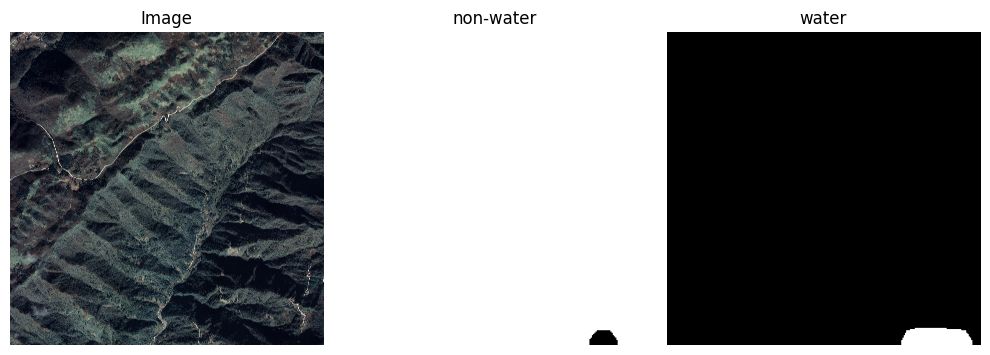

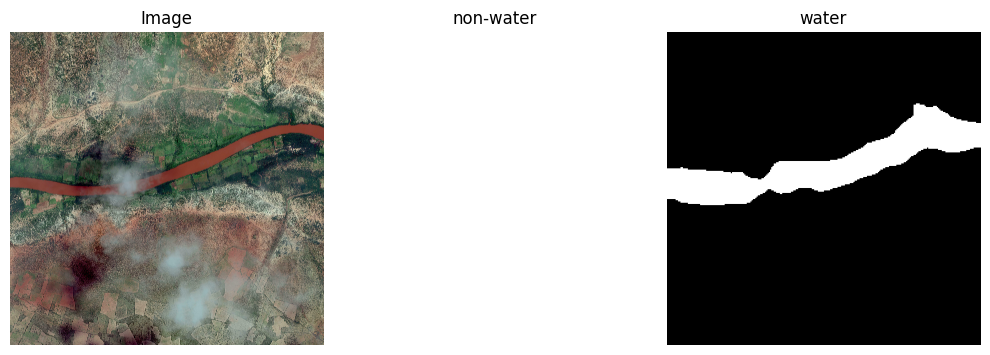

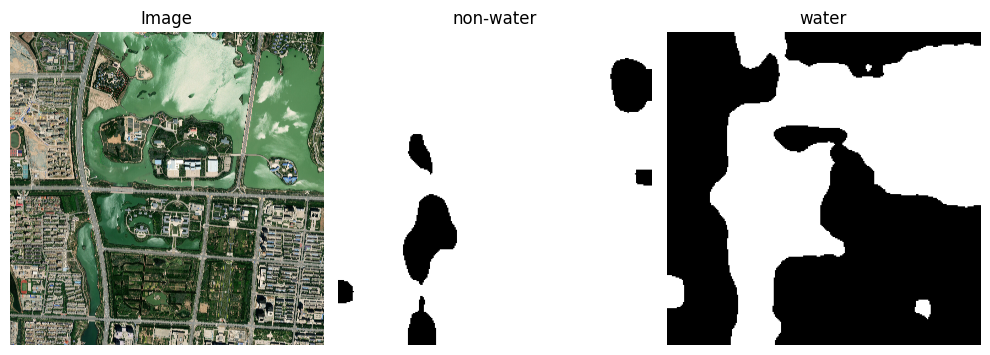

In [17]:
model_path = "/home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar"
labels = ["non-water","water"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/GLH_Water/test/img/22.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/GLH_Water/test/img/119.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/GLH_Water/test/img/162.jpg')
fig = model.predict_masks(image, labels, transform)